# 5장 1강: 일반화와 학습 안정화 기법 — 실습문제 풀이

> **풀이 기준**: 프로젝트에 업로드된 `concrete_data.csv`로 코드를 실제 실행한 결과입니다. 손실은 학습 데이터 기준으로 표준화한 목표의 MSE이며, MPa 단위가 아닙니다.
>
> **가정한 내용**: 별도 판단이 필요한 부분은 없었습니다. 제공 함수·시드·설정값을 그대로 사용했습니다. 그래프 축 이름은 한글 글꼴 문제를 피하려고 영어로 표기했습니다.

---

## 실습 준비 (제공 코드)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = Path("concrete_data.csv")
if not data_path.exists():
    data_path = Path("concrete_data(1).csv")
original = pd.read_csv(data_path)
original.columns = original.columns.str.strip()
df = original.drop_duplicates().reset_index(drop=True)
target = "concrete_compressive_strength"
features = [name for name in df.columns if name != target]
indices = np.random.default_rng(42).permutation(len(df))
train_df = df.iloc[indices[:80]].copy()
valid_df = df.iloc[indices[80:280]].copy()

train_raw = train_df[features].to_numpy(dtype=float)
valid_raw = valid_df[features].to_numpy(dtype=float)
x_mean = train_raw.mean(axis=0)
x_std = train_raw.std(axis=0)
X_train = (train_raw - x_mean) / x_std
X_valid = (valid_raw - x_mean) / x_std
y_raw = train_df[[target]].to_numpy(dtype=float)
y_valid_raw = valid_df[[target]].to_numpy(dtype=float)
y_mean = y_raw.mean()
y_std = y_raw.std()
y_train = (y_raw - y_mean) / y_std
y_valid = (y_valid_raw - y_mean) / y_std

print("원본 / 중복 제거 후:", original.shape, df.shape)
print("결측값 수:", df.isna().sum().sum())
print("학습 / 검증 / 미사용 행:", len(train_df), len(valid_df), len(df)-280)
print("입력 / 목표 크기:", X_train.shape, y_train.shape)

원본 / 중복 제거 후: (1030, 9) (1005, 9)
결측값 수: 0
학습 / 검증 / 미사용 행: 80 200 725
입력 / 목표 크기: (80, 8) (80, 1)


In [2]:
def predict(values, params):
    w1, b1, w2, b2 = params
    return np.tanh(values @ w1 + b1) @ w2 + b2


def train_demo():
    rng = np.random.default_rng(7)
    w1 = rng.normal(0.0, 0.3, size=(8, 32))
    b1 = np.zeros((1, 32))
    w2 = rng.normal(0.0, 0.1, size=(32, 1))
    b2 = np.zeros((1, 1))
    records, checkpoints = [], []
    for epoch in range(1, 1201):
        hidden = np.tanh(X_train @ w1 + b1)
        prediction = hidden @ w2 + b2
        grad_output = 2.0 * (prediction - y_train) / len(X_train)
        grad_w2 = hidden.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        grad_hidden = (grad_output @ w2.T) * (1.0 - hidden**2)
        grad_w1 = X_train.T @ grad_hidden
        grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
        w1 -= 0.03 * grad_w1
        b1 -= 0.03 * grad_b1
        w2 -= 0.03 * grad_w2
        b2 -= 0.03 * grad_b2
        params = (w1, b1, w2, b2)
        train_loss = np.mean((predict(X_train, params) - y_train)**2)
        valid_loss = np.mean((predict(X_valid, params) - y_valid)**2)
        records.append({"epoch": epoch, "train_loss": train_loss, "valid_loss": valid_loss})
        checkpoints.append(tuple(value.copy() for value in params))
    return pd.DataFrame(records), checkpoints


print("학습·예측 함수 준비 완료")

학습·예측 함수 준비 완료


In [3]:
U = train_df[["cement", "water"]].iloc[:4].to_numpy(dtype=float) / 100.0
W = np.array([[1.0, 0.5, -0.5], [0.5, -1.0, 1.0]])
b = np.array([0.0, 1.0, 2.0])
Z = U @ W + b
H = np.maximum(0.0, Z)

mask = np.array([[1, 0, 1], [0, 1, 0], [1, 1, 0], [0, 0, 1]])
print("계산용 U:", U)
print("가중합 Z:", np.round(Z, 6))
print("ReLU 활성값 H:", np.round(H, 6))

계산용 U: [[1.02  1.92 ]
 [2.    1.92 ]
 [2.149 1.556]
 [2.772 1.607]]
가중합 Z: [[ 1.98   -0.41    3.41  ]
 [ 2.96    0.08    2.92  ]
 [ 2.927   0.5185  2.4815]
 [ 3.5755  0.779   2.221 ]]
ReLU 활성값 H: [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]


In [4]:
def replay_early_stopping(history, checkpoints, patience):
    best_loss = float("inf")
    best_epoch = None
    best_params = None
    wait = 0
    trace = []
    stopped = False
    for row in history.itertuples(index=False):
        improved = row.valid_loss < best_loss
        if improved:
            best_loss = row.valid_loss
            best_epoch = int(row.epoch)
            best_params = tuple(p.copy() for p in checkpoints[best_epoch - 1])
            wait = 0
        else:
            wait += 1
        trace.append({"epoch": int(row.epoch), "valid_loss": row.valid_loss,
                      "improved": improved, "wait": wait, "best_epoch": best_epoch})
        if wait >= patience:
            stopped = True
            break
    result = {"stopped": stopped, "last_checked_epoch": trace[-1]["epoch"],
              "best_epoch": best_epoch, "best_valid_loss": best_loss}
    return result, pd.DataFrame(trace), best_params


print("Early Stopping 판단 함수 준비 완료")

Early Stopping 판단 함수 준비 완료


---

## 실습 1. 일반화와 과적합 억제

### 문제 1-1. 학습·검증 손실 함께 읽기

 epoch  train_loss  valid_loss
     1    1.309837    1.658692
   100    0.221291    0.467928
   200    0.187021    0.428178
   400    0.145534    0.399101
   600    0.122144    0.395813
   800    0.107144    0.396244
  1000    0.095320    0.396382
  1200    0.084271    0.397232

검증 손실 최저 행:
epoch         584.000000
train_loss      0.123617
valid_loss      0.395805


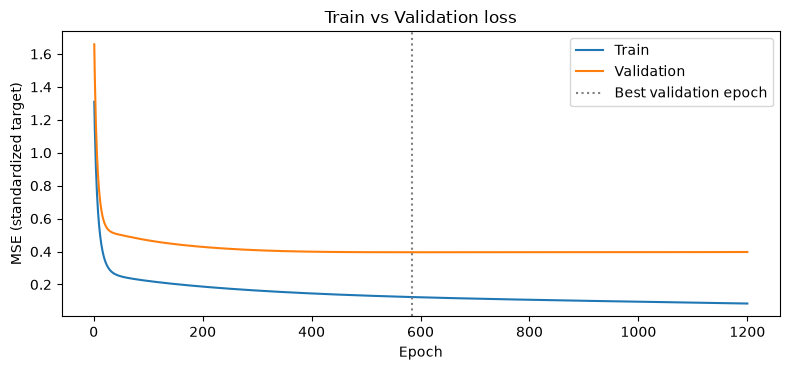

In [5]:
history, checkpoints = train_demo()
selected = history[history["epoch"].isin([1, 100, 200, 400, 600, 800, 1000, 1200])]
print(selected.round(6).to_string(index=False))

best_row = history.loc[history["valid_loss"].idxmin()]
print("\n검증 손실 최저 행:")
print(best_row.round(6).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(history["epoch"], history["train_loss"], label="Train")
ax.plot(history["epoch"], history["valid_loss"], label="Validation")
ax.axvline(best_row["epoch"], linestyle=":", color="gray", label="Best validation epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (standardized target)")
ax.set_title("Train vs Validation loss")
ax.legend()
fig.tight_layout()

#### 답변

**계산·결과 정리**

- 검증 손실 최저: **584 epoch**, 학습 0.123617 / 검증 **0.395805**
- 마지막 1200 epoch: 학습 0.084271 / 검증 0.397232
- 584 → 1200 구간: 학습 손실은 0.123617 → 0.084271로 약 32% 더 줄었지만, 검증 손실은 0.395805 → 0.397232로 약 0.0014(0.36%) 늘었습니다.

**Q1. 일반화와 과적합은 무엇인가요? 검증 손실까지 함께 봐야 하는 이유는 무엇인가요?**

- 일반화: 학습에 쓰지 않은 새 데이터에서도 예측이 잘 맞는 성질입니다.
- 과적합: 학습 데이터에 지나치게 맞춰져, 학습 손실은 계속 줄어도 새 데이터 성능은 나아지지 않거나 나빠지는 상태입니다.
- 학습 손실은 가중치를 업데이트한 바로 그 데이터에서 계산하므로 계속 줄어드는 것이 당연합니다. 새 데이터에서 어떤지는 업데이트에 쓰지 않은 검증 손실로만 확인할 수 있습니다.

**Q2. 검증 손실이 가장 작은 epoch와 그 값은 무엇인가요? 최저점 이후와 마지막 기록을 비교해 어떤 징후를 읽을 수 있나요?**

- **584 epoch, 0.395805**입니다.
- 최저점 이후 학습 손실은 0.124 → 0.084로 계속 줄었지만 검증 손실은 0.3958 → 0.3972로 소폭 늘었습니다. 학습 데이터에만 더 맞춰지고 새 데이터에는 도움이 되지 않는 **과적합의 초기 징후**입니다. 다만 악화 폭은 매우 작습니다.

**Q3. 학습 손실보다 검증 손실이 높으면 언제나 심한 과적합인가요? 이번 검증 최저값을 최종 테스트 성능으로 발표해도 되나요?**

- 아닙니다. 학습 데이터는 모델이 직접 맞춘 데이터라 검증 손실이 더 높은 것은 흔합니다. 중요한 것은 **추세**입니다. 이번에도 1~584 epoch에는 검증 손실이 학습 손실보다 높았지만 둘 다 함께 줄었으므로 정상적인 학습 구간이었습니다.
- 안 됩니다. 검증 데이터로 최적 시점을 **골랐으므로** 검증 데이터는 이미 선택에 관여했습니다. 최종 성능은 따로 남겨 둔 테스트 데이터로 확인해야 하며, 이번 자료는 테스트 평가를 하지 않았습니다.

---

### 문제 1-2. Dropout과 Weight Decay는 무엇을 바꿀까요?

In [6]:
p = 0.5
H_train = H * mask / (1 - p)
H_eval = H

G = np.full_like(W, 0.2)
lr = 0.1
decay = 0.5
W_plain = W - lr * G
W_decay = (1 - lr * decay) * W - lr * G

print("H:\n", np.round(H, 6))
print("mask:\n", mask)
print("H_train (Dropout 학습):\n", np.round(H_train, 6))
print("H_eval (평가):\n", np.round(H_eval, 6))
print("W:\n", W)
print("W_plain:\n", np.round(W_plain, 6))
print("W_decay:\n", np.round(W_decay, 6))

H:
 [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]
mask:
 [[1 0 1]
 [0 1 0]
 [1 1 0]
 [0 0 1]]
H_train (Dropout 학습):
 [[3.96  0.    6.82 ]
 [0.    0.16  0.   ]
 [5.854 1.037 0.   ]
 [0.    0.    4.442]]
H_eval (평가):
 [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]
W:
 [[ 1.   0.5 -0.5]
 [ 0.5 -1.   1. ]]
W_plain:
 [[ 0.98  0.48 -0.52]
 [ 0.48 -1.02  0.98]]
W_decay:
 [[ 0.93   0.455 -0.495]
 [ 0.455 -0.97   0.93 ]]


#### 답변

**계산 과정**

- Dropout 첫 행: H[0] = [1.98, 0, 3.41], mask = [1, 0, 1]
  - [1.98 × 1, 0 × 0, 3.41 × 1] / (1 − 0.5) = [1.98, 0, 3.41] / 0.5 = **[3.96, 0, 6.82]**
  - 평가: **[1.98, 0, 3.41]** (그대로)
- Weight Decay, W 첫 원소 1.0
  - 일반: 1.0 − 0.1 × 0.2 = 1.0 − 0.02 = **0.98**
  - decay 포함: (1 − 0.1 × 0.5) × 1.0 − 0.02 = 0.95 − 0.02 = **0.93**

**Q1. 첫 행 Dropout 결과는 무엇인가요? 유지된 값에 2를 곱하는 이유는 무엇인가요?**

- **[3.96, 0, 6.82]**입니다. 두 번째 값은 원래 0이었고 마스크로도 제거되었습니다.
- p = 0.5로 평균적으로 절반이 꺼지므로, 남은 값을 1/(1 − p) = 2배로 키워 **다음 층이 받는 값의 기대 크기를 평가 때와 비슷하게** 맞추기 위해서입니다. 그래서 평가 때는 보정 없이 원래 값을 그대로 쓸 수 있습니다.

**Q2. Dropout은 뉴런이나 가중치를 영구 삭제하나요? 평가에서도 같은 마스크와 2배 계산을 적용하나요?**

- 아닙니다. 학습 중 **매번 무작위로 일부 활성값을 임시로** 0으로 만들 뿐이며, 가중치와 뉴런은 그대로 남아 있습니다.
- 평가에서는 Dropout을 끄고 마스크와 2배 보정 모두 적용하지 않습니다(H_eval = H).

**Q3. W의 첫 값은 decay 전후 업데이트에서 각각 얼마인가요? decay 항이 하는 일과 전체 업데이트의 방향을 구분해서 설명하세요.**

- 일반 업데이트 **0.98**, decay 포함 **0.93**입니다.
- decay 항(−lr × λ × W = −0.05)은 가중치를 **0 쪽으로 당기는** 역할만 합니다. 전체 업데이트 방향은 데이터 기울기 항(−lr × G)과 decay 항을 합친 결과로 정해집니다. 이번에는 두 항이 모두 값을 줄이는 방향이라 0.07만큼 줄었지만, 데이터 기울기가 음수로 크면 decay가 있어도 가중치가 커질 수 있습니다.

**Q4. 두 기법이 과적합을 줄이는 데 도움이 되는 이유는 무엇인가요? 이 작은 계산으로 성능 향상이 입증되었나요?**

- Dropout: 특정 뉴런 몇 개에 지나치게 의존하지 못하게 해 여러 뉴런이 고르게 쓰이는, 더 견고한 표현을 배우게 합니다.
- Weight Decay: 가중치가 지나치게 커지는 것을 막아 더 단순하고 완만한 함수를 학습하게 해 학습 데이터의 잡음에 덜 맞춥니다.
- 입증되지 않았습니다. 이번 계산은 동작 원리만 확인했고, 진단용 학습 모델에는 두 기법을 적용하지 않았으므로 검증 성능 변화는 측정하지 않았습니다.

---

## 실습 2. 학습 안정화와 중단 시점

### 문제 2-1. Batch Normalization의 학습·평가 계산

In [7]:
eps = 1e-5
gamma = np.ones(3)
beta = np.zeros(3)
batch_mean = Z.mean(axis=0)
batch_var = Z.var(axis=0, ddof=0)
x_hat = (Z - batch_mean) / np.sqrt(batch_var + eps)
bn_train = gamma * x_hat + beta

running_mean = np.array([4.0, 1.0, 2.0])
running_var = np.array([1.0, 0.25, 0.5])
bn_eval = gamma * (Z[:1] - running_mean) / np.sqrt(running_var + eps) + beta

print("Z:\n", np.round(Z, 6))
print("배치 평균:", np.round(batch_mean, 6))
print("배치 분산:", np.round(batch_var, 6))
print("BN 학습 결과:\n", np.round(bn_train, 6))
print("결과 열별 평균:", np.round(bn_train.mean(axis=0), 6))
print("결과 열별 분산:", np.round(bn_train.var(axis=0), 6))
print("BN 평가 결과 (Z 첫 행):", np.round(bn_eval, 6))

Z:
 [[ 1.98   -0.41    3.41  ]
 [ 2.96    0.08    2.92  ]
 [ 2.927   0.5185  2.4815]
 [ 3.5755  0.779   2.221 ]]
배치 평균: [2.860625 0.241875 2.758125]
배치 분산: [0.325207 0.204042 0.204042]
BN 학습 결과:
 [[-1.544203 -1.443091  1.443091]
 [ 0.174257 -0.358351  0.358351]
 [ 0.116391  0.61238  -0.61238 ]
 [ 1.253555  1.189062 -1.189062]]
결과 열별 평균: [ 0. -0. -0.]
결과 열별 분산: [0.999969 0.999951 0.999951]
BN 평가 결과 (Z 첫 행): [[-2.01999  -2.819944  1.994021]]


#### 답변

**대입 식 (첫 특징)**

- 학습: (1.98 − 2.860625) / √(0.325207 + 0.00001) = −0.880625 / 0.570278 ≈ **−1.544203** → γ·x̂ + β = 1 × (−1.544203) + 0 = **−1.544203**
- 평가: (1.98 − 4.0) / √(1.0 + 0.00001) = −2.02 / 1.000005 ≈ **−2.019990**

**Q1. Z의 열별 평균과 분산은 무엇인가요? axis=0으로 계산하는 이유는 무엇인가요?**

- 평균 **[2.860625, 0.241875, 2.758125]**, 분산 **[0.325207, 0.204042, 0.204042]**입니다.
- BN은 **특징(뉴런)마다** 배치 안의 샘플들에 걸쳐 통계를 구합니다. axis=0은 행(샘플 4개) 방향으로 모아 계산하므로 열(특징)별 평균·분산이 나옵니다.

**Q2. 첫 행 첫 특징의 학습 결과는 얼마인가요? 결과 평균·분산은 어떤 값에 가깝고, gamma·beta가 바뀌어도 항상 같은가요?**

- 약 **−1.544203**입니다.
- 결과의 열별 평균은 거의 **0**(소수점 오차 수준), 분산은 거의 **1**(ε 때문에 0.99995~0.99997)입니다.
- gamma·beta가 바뀌면 달라집니다. 결과 평균은 β, 표준편차는 약 γ가 되므로, 이번에는 γ = 1, β = 0이라 0과 1에 가까웠을 뿐입니다.

**Q3. 첫 행 평가 결과는 무엇인가요? 학습 때와 다른 숫자가 나오는 이유는 무엇인가요?**

- **[−2.019990, −2.819944, 1.994021]**입니다.
- 학습 때는 **현재 배치 4개의 평균·분산**을 쓰지만, 평가 때는 학습 중 누적해 둔 **running 통계**(이번에는 제공한 예시 값 [4, 1, 2], [1, 0.25, 0.5])를 씁니다. 기준 통계가 다르니 결과도 다릅니다.

**Q4. BN은 평가 때 꺼지는 Dropout과 같나요? 입력 데이터 표준화와 같은 작업인가요? 과적합을 항상 해결하나요?**

- 다릅니다. Dropout은 평가 때 꺼지지만, BN은 평가 때도 **켜져 있고 저장 통계를 사용하는 방식으로 바뀔** 뿐입니다.
- 입력 데이터 표준화와도 다릅니다. 입력 표준화는 학습 전에 원본 특성을 고정 기준으로 한 번 바꾸지만, BN은 신경망 **내부 층**에서 배치마다 통계를 구하고, 학습되는 γ·β로 다시 조절합니다.
- 항상 해결하지 않습니다. BN은 주로 학습을 안정시키고 빠르게 하는 기법이며, 약간의 규제 효과가 있을 수 있지만 과적합 해결을 보장하지 않습니다.

---

### 문제 2-2. Early Stopping으로 멈출 때와 복원할 때 구분하기

In [8]:
result20, trace20, best_params = replay_early_stopping(history, checkpoints, patience=20)
restored_loss = np.mean((predict(X_valid, best_params) - y_valid)**2)

print("판단 요약:", {k: (round(v, 6) if isinstance(v, float) else v) for k, v in result20.items()})
print()
print(trace20.tail(22).round(6).to_string(index=False))
print()
print("복원 가중치의 검증 손실:", round(restored_loss, 6))
print("저장된 최저 검증 손실 :", round(result20["best_valid_loss"], 6))
print("두 값이 같은가?:", np.isclose(restored_loss, result20["best_valid_loss"]))
stop_loss = history.loc[history["epoch"] == result20["last_checked_epoch"], "valid_loss"].iloc[0]
print("중단 시점(", result20["last_checked_epoch"], "epoch) 가중치의 검증 손실:", round(stop_loss, 6))

판단 요약: {'stopped': True, 'last_checked_epoch': 604, 'best_epoch': 584, 'best_valid_loss': 0.395805}

 epoch  valid_loss  improved  wait  best_epoch
   583    0.395805      True     0         583
   584    0.395805      True     0         584
   585    0.395805     False     1         584
   586    0.395805     False     2         584
   587    0.395805     False     3         584
   588    0.395805     False     4         584
   589    0.395806     False     5         584
   590    0.395806     False     6         584
   591    0.395806     False     7         584
   592    0.395807     False     8         584
   593    0.395807     False     9         584
   594    0.395808     False    10         584
   595    0.395809     False    11         584
   596    0.395809     False    12         584
   597    0.395810     False    13         584
   598    0.395811     False    14         584
   599    0.395812     False    15         584
   600    0.395813     False    16         584
   601

#### 답변

**계산·결과 정리**

- 마지막 개선: 584 epoch(검증 0.395805) → 585~604 epoch까지 20번 연속 개선 없음 → **604 epoch에서 중단**
- 복원: **584 epoch**의 체크포인트, 복원 검증 손실 **0.395805**(저장된 최저값과 일치)

**Q1. 중단 시점과 복원할 최적 epoch는 각각 언제인가요? 서로 다른 이유는 무엇인가요?**

- 중단 **604 epoch**, 복원 **584 epoch**입니다.
- 584 epoch가 최저였는지는 그 뒤로 개선이 없는 것을 **확인한 뒤에야** 알 수 있습니다. 그래서 patience만큼(20 epoch) 더 기다린 뒤 멈추고, 가장 좋았던 시점으로 돌아갑니다.

**Q2. 기다린 횟수는 어떤 때 0으로 돌아가나요? patience=20은 전체 학습을 20 epoch만 한다는 뜻인가요?**

- 검증 손실이 **지금까지의 최저값보다 엄격히 작아졌을 때** 0으로 돌아갑니다.
- 아닙니다. "개선이 없는 epoch가 **연속 20번**이면 멈춘다"는 뜻입니다. 이번에는 604 epoch까지 학습했습니다.

**Q3. 복원된 가중치로 계산한 검증 손실은 얼마인가요? 중단한 시점의 가중치를 그대로 쓰는 것과 무엇이 다른가요?**

- **0.395805**로, 저장된 최저 검증 손실과 같습니다.
- 중단 시점(604 epoch)의 가중치는 584 이후 20 epoch를 더 학습한 상태라, 검증 손실이 **0.395817**로 최저보다 약간 높습니다. 복원하면 검증 기준으로 가장 좋았던 가중치를 쓰게 됩니다.

**Q4. Early Stopping은 실제로 기울기나 모델 구조를 바꾸나요? 이번 기록 재생이 실제 학습 시간을 줄인 실험인가요?**

- 바꾸지 않습니다. 업데이트 식·모델 구조는 그대로이고, **학습을 언제 멈추고 어떤 가중치를 남길지**만 정합니다.
- 아닙니다. 이미 1200 epoch를 모두 학습한 기록을 시간 순서대로 다시 읽은 것입니다. 실제로 시간을 줄이려면 같은 판단을 학습 반복문 안에 넣어야 합니다.

---

## 기초 과제. 중단 규칙과 기법의 역할 복습

### 문제 3-1. 기다리는 횟수만 바꾸기

In [9]:
result10, trace10, params10 = replay_early_stopping(history, checkpoints, patience=10)
loss10 = np.mean((predict(X_valid, params10) - y_valid)**2)

compare = pd.DataFrame([
    {"patience": 20, "stop_epoch": result20["last_checked_epoch"], "best_epoch": result20["best_epoch"],
     "best_valid_loss": result20["best_valid_loss"], "restored_loss": restored_loss},
    {"patience": 10, "stop_epoch": result10["last_checked_epoch"], "best_epoch": result10["best_epoch"],
     "best_valid_loss": result10["best_valid_loss"], "restored_loss": loss10},
])
print(compare.round(6).to_string(index=False))

 patience  stop_epoch  best_epoch  best_valid_loss  restored_loss
       20         604         584         0.395805       0.395805
       10         594         584         0.395805       0.395805


#### 답변

**네 기법의 역할 정리**

| 기법 | 바꾸는 대상 | 평가 때의 동작 |
|---|---|---|
| Dropout | 학습 중 활성값(일부를 임시로 0, 나머지는 보정) | 꺼짐(모든 활성값 그대로) |
| Weight Decay | 가중치 업데이트(0 방향으로 당기는 항 추가) | 별도 동작 없음(학습된 가중치 사용) |
| Batch Normalization | 층 내부 값의 분포(배치 통계로 정규화 + γ·β) | 켜져 있음, 저장한 running 통계 사용 |
| Early Stopping | 학습을 멈추는 시점과 남길 가중치 | 별도 동작 없음(복원한 가중치 사용) |

**Q1. patience=10의 중단 epoch, 최적 epoch, 복원 손실은 무엇인가요? patience=20과 어떤 차이가 있나요?**

- 중단 **594 epoch**, 최적 **584 epoch**, 복원 손실 **0.395805**입니다.
- patience = 20보다 **10 epoch 일찍** 멈췄지만, 최적 epoch와 복원 손실은 같습니다.

**Q2. patience가 작을수록 항상 일반화 성능이 좋아지나요? 이번 결과를 근거로 설명하세요.**

- 아닙니다. 이번에는 584 이후 다시 개선되지 않아서 둘 다 같은 시점을 복원했습니다. 하지만 검증 손실은 잠깐 정체했다가 다시 내려가기도 하므로, patience가 너무 작으면 **더 좋아질 수 있었던 학습을 일찍 끊을** 위험이 있습니다. patience가 작으면 학습 시간이 줄어드는 장점은 있지만 성능 향상을 보장하지는 않습니다.

**Q3. 네 기법의 역할과 평가 때의 동작을 정리하세요. 이들을 모두 켜면 반드시 가장 좋은 모델이 되나요?**

- 역할과 평가 동작은 위 표와 같습니다.
- 그렇지 않습니다. 각 기법의 효과는 데이터·모델·설정값(p, λ, patience 등)에 따라 다르고, 과하게 쓰면 오히려 **과소적합**이 생길 수 있습니다. 같은 조건에서 검증 성능으로 비교해 골라야 합니다.

---

## 실습 마무리

**마무리 Q1. 일반화와 과적합을 구분하고, 이번 손실 기록에서 과적합 징후를 판단한 수치와 이유를 쓰세요. 학습 손실만 보면 어떤 점을 놓치나요?**

- 일반화는 새 데이터에서도 잘 맞는 능력이고, 과적합은 학습 데이터에만 지나치게 맞춰진 상태입니다.
- 584 epoch 이후 학습 손실은 0.1236 → 0.0843으로 계속 줄었지만, 검증 손실은 0.3958 → 0.3972로 소폭 늘었습니다. 학습은 좋아지는데 검증은 나빠지므로 과적합의 초기 징후입니다.
- 학습 손실만 보면 1200 epoch가 가장 좋아 보여, 검증 성능이 이미 나빠지기 시작했다는 사실을 놓칩니다.

**마무리 Q2. H 첫 행 [1.98, 0, 3.41]과 마스크 [1, 0, 1], 제거 확률 0.5로 학습·평가 Dropout 결과를 구하세요.**

- 학습: [1.98, 0, 3.41] × [1, 0, 1] / 0.5 = **[3.96, 0, 6.82]**
- 평가: **[1.98, 0, 3.41]**
- 두 배 보정은 절반이 꺼진 상태에서도 다음 층이 받는 값의 기대 크기를 평가 때와 맞추기 위한 것입니다.

**마무리 Q3. w=1, G=0.2, lr=0.1, decay=0.5일 때 일반 업데이트와 decay 포함 결과를 계산하세요. 음수 가중치에도 decay가 0 방향으로 작용하는 이유를 쓰세요.**

- 일반: 1 − 0.1 × 0.2 = **0.98**
- decay 포함: (1 − 0.1 × 0.5) × 1 − 0.02 = 0.95 − 0.02 = **0.93**
- decay 항은 W에 (1 − lr·λ) = 0.95를 곱하므로, 부호와 관계없이 크기만 5% 줄입니다. 예를 들어 −1은 −0.95가 되어 0에 가까워집니다.

**마무리 Q4. BN에서 axis=0, epsilon, gamma·beta가 각각 무엇을 하는지 설명하세요. 첫 특징의 학습값과 평가값이 다른 이유와 평가에서도 BN이 필요한 이유를 쓰세요.**

- axis=0: 배치의 샘플들에 걸쳐 특징(열)별 평균·분산을 구합니다.
- epsilon: 분산이 0에 가까울 때 0으로 나누는 것을 막는 작은 수입니다.
- gamma·beta: 정규화한 값의 크기와 위치를 다시 조절하는 학습 가능한 값입니다.
- 첫 특징은 학습 −1.544203, 평가 −2.019990입니다. 학습은 현재 배치 통계, 평가는 저장된 running 통계를 쓰기 때문에 다릅니다.
- 모델이 정규화된 분포를 기준으로 학습되었으므로, 평가 때도 같은 변환을 해야 예측이 맞습니다. 다만 평가 때는 배치 구성에 따라 결과가 흔들리지 않도록 고정 통계를 씁니다.

**마무리 Q5. 584 epoch에서 마지막으로 개선된 뒤 개선이 없을 때 patience=20과 10은 각각 언제 중단하고 어느 시점을 복원하나요? 입력된 전체 기록을 미리 보고 중단하는 규칙인가요?**

- patience = 20: **604 epoch** 중단, **584 epoch** 복원
- patience = 10: **594 epoch** 중단, **584 epoch** 복원
- 아닙니다. 기록을 처음부터 시간 순서대로 읽으며 **지금까지 본 정보만으로** 판단합니다. 미래 기록을 미리 보지 않습니다.

**마무리 Q6. Dropout·Weight Decay·BN·Early Stopping을 바꾸는 대상과 평가 시 동작으로 비교하세요. 이번 자료에서 실제로 검증한 내용과 아직 입증하지 않은 내용을 구분하세요.**

- 비교는 과제 3-1의 표와 같습니다.
- 실제로 확인한 것: 실제 학습 기록에서 과적합 징후(584 epoch 이후 검증 손실 소폭 증가), Early Stopping의 중단·복원 시점과 복원 손실, 세 기법(Dropout·Weight Decay·BN)이 작은 예제에서 값을 어떻게 바꾸는지
- 입증하지 않은 것: Dropout·Weight Decay·BN을 학습에 실제로 적용했을 때의 검증 성능 개선, 최종 테스트 성능, 다른 설정값에서의 결과